<a href="https://colab.research.google.com/github/divithashree/C-programming-assignment-/blob/main/Find_S_Algorithm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Training Dataset ---
     Sky AirTemp Humidity    Wind Water Forecast EnjoySport
0  Sunny    Warm   Normal  Strong  Warm     Same        Yes
1  Sunny    Warm     High  Strong  Warm     Same        Yes
2  Rainy    Cold     High  Strong  Warm   Change         No
3  Sunny    Warm     High  Strong  Cool   Change        Yes


Final Most Specific Hypothesis:
['Sunny', 'Warm', '?', 'Strong', '?', '?']



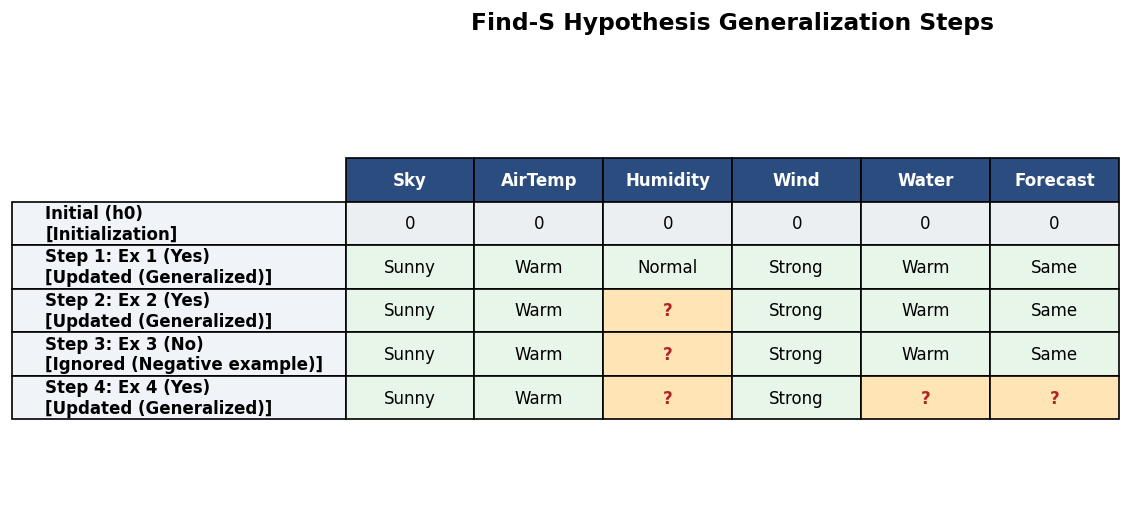

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# -------------------------------------------------------------
# 1. Dataset Setup (Classic "EnjoySport" concept learning task)
# -------------------------------------------------------------
data = {
    'Sky': ['Sunny', 'Sunny', 'Rainy', 'Sunny'],
    'AirTemp': ['Warm', 'Warm', 'Cold', 'Warm'],
    'Humidity': ['Normal', 'High', 'High', 'High'],
    'Wind': ['Strong', 'Strong', 'Strong', 'Strong'],
    'Water': ['Warm', 'Warm', 'Warm', 'Cool'],
    'Forecast': ['Same', 'Same', 'Change', 'Change'],
    'EnjoySport': ['Yes', 'Yes', 'No', 'Yes']  # Target concept
}

df = pd.DataFrame(data)
features = df.columns[:-1].tolist()
target_col = df.columns[-1]

print("--- Training Dataset ---")
print(df)
print("\n" + "="*50 + "\n")

# -------------------------------------------------------------
# 2. Find-S Algorithm Implementation
# -------------------------------------------------------------
def find_s(df, feature_cols, target_col, positive_label='Yes'):
    # Initialize to the most specific hypothesis
    h = ['0'] * len(feature_cols)
    history = [('Initial (h0)', list(h), 'Initialization')]

    step = 1
    for idx, row in df.iterrows():
        label = row[target_col]
        example = row[feature_cols].tolist()

        if label == positive_label:
            # First positive example sets the concrete baseline if still all '0'
            if h == ['0'] * len(feature_cols):
                h = list(example)
            else:
                for i in range(len(h)):
                    if h[i] != example[i]:
                        h[i] = '?'  # Generalize attribute
            history.append((f'Step {step}: Ex {idx+1} (Yes)', list(h), 'Updated (Generalized)'))
        else:
            # Negative examples are ignored by Find-S
            history.append((f'Step {step}: Ex {idx+1} (No)', list(h), 'Ignored (Negative example)'))

        step += 1

    return h, history

final_hypothesis, history = find_s(df, features, target_col)

print(f"Final Most Specific Hypothesis:\n{final_hypothesis}\n")

# -------------------------------------------------------------
# 3. Matplotlib Visualization (Google Colab Ready)
# -------------------------------------------------------------
# Table layout showing the hypothesis state at each step
table_data = []
row_labels = []

for step_name, hyp, note in history:
    row_labels.append(f"{step_name}\n[{note}]")
    table_data.append(hyp)

fig, ax = plt.subplots(figsize=(10, 4.5), dpi=120)
ax.axis('off')

# Render hypothesis history as a formatted table
table = ax.table(
    cellText=table_data,
    rowLabels=row_labels,
    colLabels=features,
    loc='center',
    cellLoc='center'
)

# Style the table
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 2.0)

# Color coding: Highlight cells that generalized to '?'
for (r, c), cell in table.get_celld().items():
    if r == 0:
        cell.set_facecolor('#2B4C7E')
        cell.set_text_props(color='white', weight='bold')
    elif c == -1:
        cell.set_facecolor('#F0F4F8')
        cell.set_text_props(weight='bold')
    else:
        val = table_data[r - 1][c]
        if val == '?':
            cell.set_facecolor('#FFE4B5')  # Light orange for generalized
            cell.set_text_props(weight='bold', color='#B22222')
        elif val == '0':
            cell.set_facecolor('#ECEFF1')  # Grey for null/specific
        else:
            cell.set_facecolor('#E8F5E9')  # Light green for specific values

plt.title("Find-S Hypothesis Generalization Steps", fontsize=14, weight='bold', pad=20)
plt.tight_layout()
plt.show()